# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Read data

In [2]:
df = pd.read_csv(r'/Users/pawn/Downloads/telecom_churn.csv')
df.head()

,Tenure_Months,Monthly_Charges,Contract_Type,Tech_Support,Internet_Service,Age,Churn
0,52,85.735348,One_Year,No,Fiber_Optic,73,0
1,15,67.228180,Month-to-Month,No,No,61,1
2,61,108.015674,Month-to-Month,No,No,43,1
3,21,41.574068,Two_Year,Yes,DSL,26,0
4,24,87.781320,One_Year,No,DSL,18,0


In [3]:
df.shape

(3000, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Tenure_Months     3000 non-null   int64  
 1   Monthly_Charges   2920 non-null   float64
 2   Contract_Type     3000 non-null   object 
 3   Tech_Support      3000 non-null   object 
 4   Internet_Service  3000 non-null   object 
 5   Age               3000 non-null   int64  
 6   Churn             3000 non-null   int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 164.2+ KB


In [5]:
df.describe()

,Tenure_Months,Monthly_Charges,Age,Churn
count,3000.000000,2920.000000,3000.000000,3000.000000
mean,35.344333,69.374133,45.731667,0.578000
std,20.355013,28.764391,16.605749,0.493961
min,1.000000,20.001163,18.000000,0.000000
25%,18.000000,44.693513,31.000000,0.000000
50%,35.000000,68.754984,46.000000,1.000000
75%,53.000000,93.891675,60.000000,1.000000
max,71.000000,119.955770,74.000000,1.000000


# Data Visualization

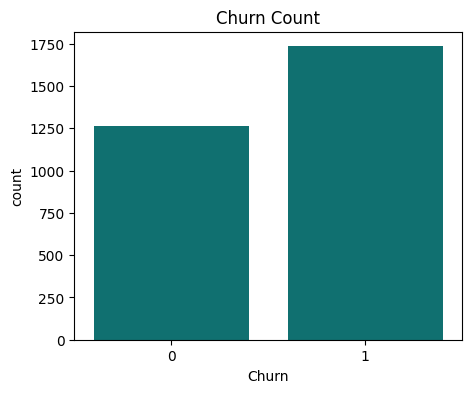

In [6]:
plt.figure(figsize=(5, 4))
sns.countplot(x='Churn', data=df, color='teal')
plt.title('Churn Count')
plt.show()

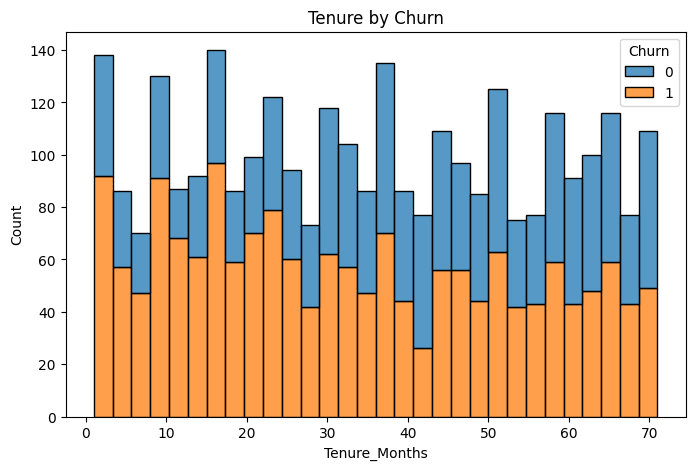

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Tenure_Months', hue='Churn', bins=30, multiple='stack')
plt.title('Tenure by Churn')
plt.show()

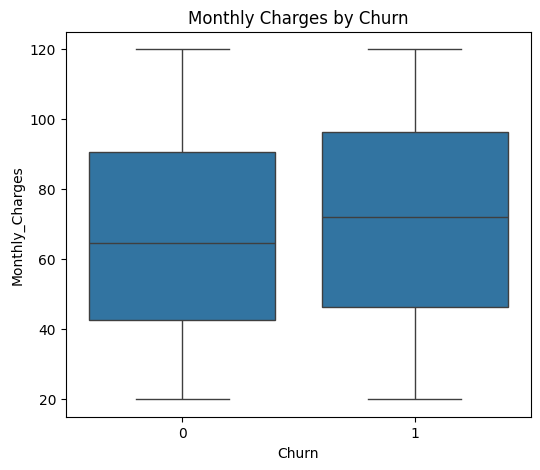

In [8]:
plt.figure(figsize=(6, 5))
sns.boxplot(x='Churn', y='Monthly_Charges', data=df)
plt.title('Monthly Charges by Churn')
plt.show()

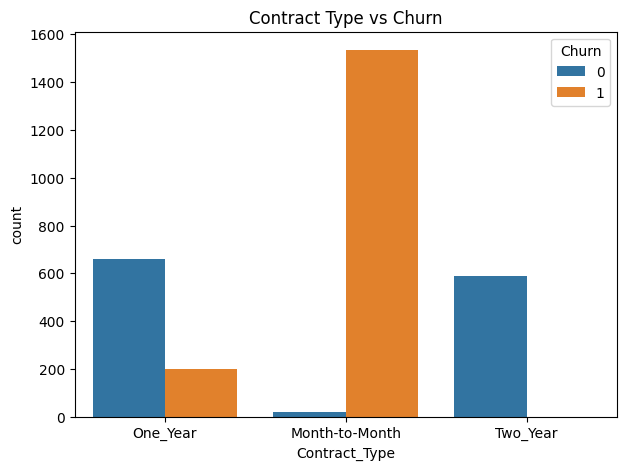

In [9]:
plt.figure(figsize=(7, 5))
sns.countplot(x='Contract_Type', hue='Churn', data=df)
plt.title('Contract Type vs Churn')
plt.show()

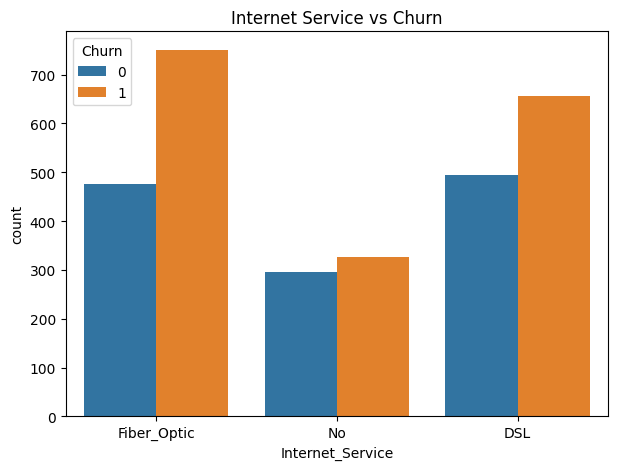

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(x='Internet_Service', hue='Churn', data=df)
plt.title('Internet Service vs Churn')
plt.show()

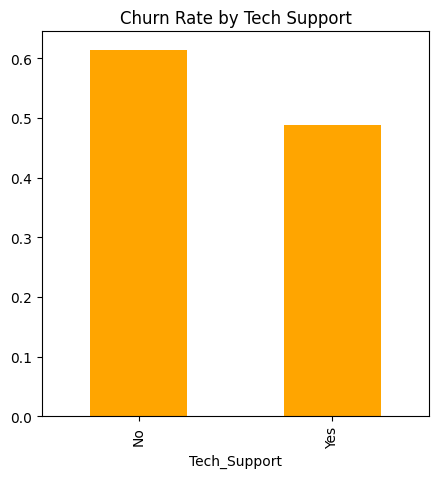

In [11]:
plt.figure(figsize=(5, 5))
df.groupby('Tech_Support')['Churn'].mean().plot(kind='bar', color='orange')
plt.title('Churn Rate by Tech Support')
plt.show()

# Data Cleaning duplicated

In [12]:
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)

Number of duplicate rows :  0


# Data Cleaning missing Value

In [13]:
df.isnull().sum().sort_values(ascending=False)

Monthly_Charges     80
Tenure_Months        0
Contract_Type        0
Tech_Support         0
Internet_Service     0
Age                  0
Churn                0
dtype: int64

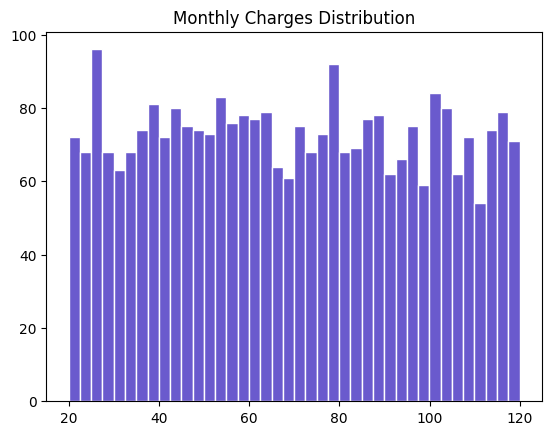

In [14]:
plt.hist(df['Monthly_Charges'].dropna(), bins=40, color='slateblue', edgecolor='white')
plt.title('Monthly Charges Distribution')
plt.show()

In [15]:
df['Monthly_Charges'].skew()

0.03307830946421047

In [16]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
df[['Monthly_Charges']] = imputer.fit_transform(df[['Monthly_Charges']])

In [17]:
df.isnull().sum().sort_values(ascending=False)

Tenure_Months       0
Monthly_Charges     0
Contract_Type       0
Tech_Support        0
Internet_Service    0
Age                 0
Churn               0
dtype: int64

# Data Encoding

## Label Encoder

In [18]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Tech_Support'] = le.fit_transform(df['Tech_Support'])
le.classes_

array(['No', 'Yes'], dtype=object)

## Ordinal Encoding

In [19]:
from sklearn.preprocessing import OrdinalEncoder

ord_enc = OrdinalEncoder(categories=[['Month-to-Month', 'One_Year', 'Two_Year']])
df[['Contract_Type']] = ord_enc.fit_transform(df[['Contract_Type']])

## OneHotEncoder

In [20]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).set_output(transform='pandas')
encoded = ohe.fit_transform(df[['Internet_Service']])
df = pd.concat([df.drop(columns='Internet_Service'), encoded], axis=1)
df.head()

,Tenure_Months,Monthly_Charges,Contract_Type,Tech_Support,Age,Churn,Internet_Service_DSL,Internet_Service_Fiber_Optic,Internet_Service_No
0,52,85.735348,1.0,0,73,0,0.0,1.0,0.0
1,15,67.228180,0.0,0,61,1,0.0,0.0,1.0
2,61,108.015674,0.0,0,43,1,0.0,0.0,1.0
3,21,41.574068,2.0,1,26,0,1.0,0.0,0.0
4,24,87.781320,1.0,0,18,0,1.0,0.0,0.0


# Outliers

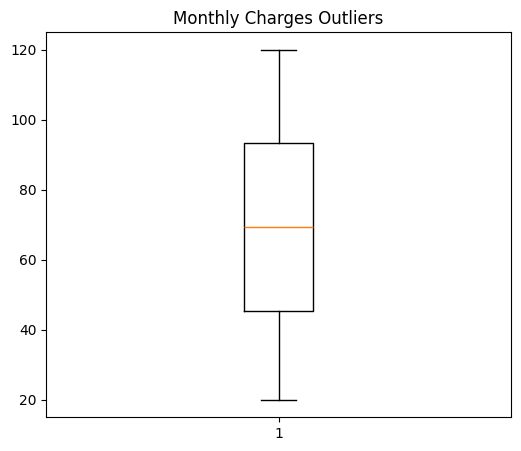

In [21]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['Monthly_Charges'])
plt.title('Monthly Charges Outliers')
plt.show()

## IQR

In [22]:
q1 = df['Monthly_Charges'].quantile(0.25)
q3 = df['Monthly_Charges'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

df = df[(df['Monthly_Charges'] >= lower) & (df['Monthly_Charges'] <= upper)]
df.reset_index(drop=True, inplace=True)
df.shape

(3000, 9)

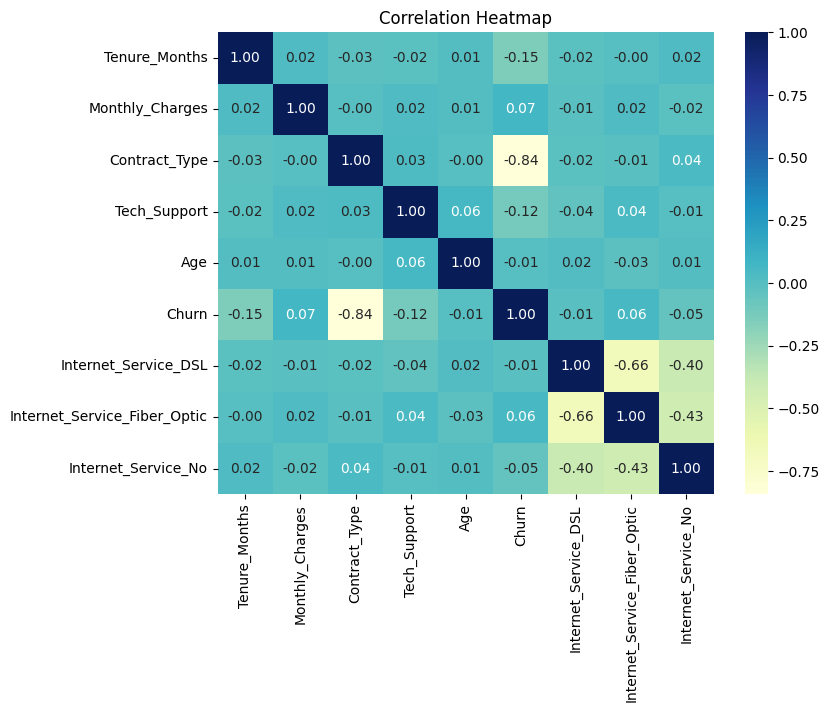

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Correlation Heatmap')
plt.show()

# Split data

In [24]:
X = df.drop('Churn', axis=1)
y = df[['Churn']]
y.value_counts()

Churn
1        1734
0        1266
Name: count, dtype: int64

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=100, stratify=y)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (2400, 8)  y_train =  (2400, 1)
X_test  =  (600, 8)  y_test  =  (600, 1)


# Scaling

In [26]:
from sklearn.preprocessing import MinMaxScaler

my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

# Models

## Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

y_train = y_train.values.ravel()
y_test = y_test.values.ravel()

model = LogisticRegression(C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, model.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Train accuracy: 0.9891666666666666
Test accuracy: 0.9766666666666667
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       253
           1       0.99      0.97      0.98       347

    accuracy                           0.98       600
   macro avg       0.98      0.98      0.98       600
weighted avg       0.98      0.98      0.98       600



## KNN

In [28]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, knn.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

Train accuracy:

 0.9895833333333334
Test accuracy: 0.9816666666666667
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       253
           1       0.99      0.98      0.98       347

    accuracy                           0.98       600
   macro avg       0.98      0.98      0.98       600
weighted avg       0.98      0.98      0.98       600



## Naive Bayes

In [29]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, gnb.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_gnb))
print(classification_report(y_test, y_pred_gnb))

Train accuracy: 0.9279166666666666
Test accuracy: 0.9216666666666666
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       253
           1       0.98      0.88      0.93       347

    accuracy                           0.92       600
   macro avg       0.92      0.93      0.92       600
weighted avg       0.93      0.92      0.92       600



## SVC

In [30]:
from sklearn.svm import SVC

svc = SVC(C=0.1, kernel='linear', gamma='auto')
svc.fit(X_train, y_train)

y_pred_svc = svc.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, svc.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_svc))
print(classification_report(y_test, y_pred_svc))

Train accuracy: 0.9279166666666666
Test accuracy: 0.9216666666666666
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       253
           1       0.98      0.88      0.93       347

    accuracy                           0.92       600
   macro avg       0.92      0.93      0.92       600
weighted avg       0.93      0.92      0.92       600



## Decision Tree

In [31]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=100)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, dt.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Train accuracy: 0.9733333333333334
Test accuracy: 0.9683333333333334


              precision    recall  f1-score   support

           0       0.99      0.93      0.96       253
           1       0.95      0.99      0.97       347

    accuracy                           0.97       600
   macro avg       0.97      0.96      0.97       600
weighted avg       0.97      0.97      0.97       600



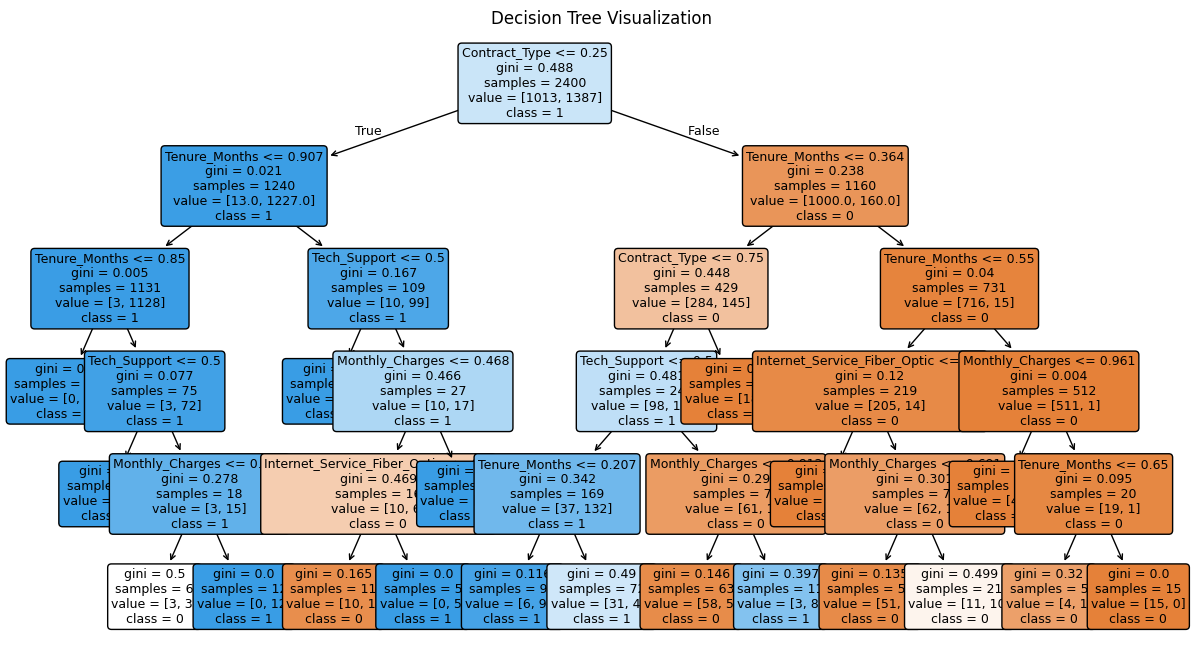

In [32]:
plt.figure(figsize=(15, 8))
plot_tree(dt, feature_names=X.columns.tolist(), class_names=[str(c) for c in dt.classes_], filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Visualization')
plt.show()

## GridSearchCV (Decision Tree)

In [33]:
from sklearn.model_selection import GridSearchCV

grid_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

grid = GridSearchCV(estimator=DecisionTreeClassifier(random_state=100), param_grid=grid_params, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print(grid.best_params_)
y_pred_best = best_model.predict(X_test)
print('Test accuracy:', accuracy_score(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Test accuracy: 0.985
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       253
           1       0.99      0.99      0.99       347

    accuracy                           0.98       600
   macro avg       0.98      0.98      0.98       600
weighted avg       0.99      0.98      0.99       600



## Random Forest

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, rf.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Train accuracy: 1.0
Test accuracy: 0.9883333333333333
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       253
           1       0.99      0.99      0.99       347

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



## Models comparison

Naive Bayes             0.921667
SVC                     0.921667
Decision Tree           0.968333
Logistic Regression     0.976667
KNN                     0.981667
Decision Tree (Grid)    0.985000
Random Forest           0.988333
dtype: float64


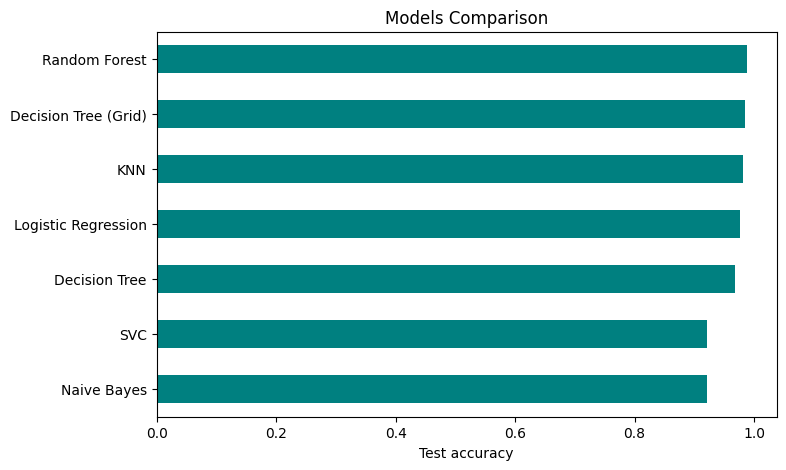

In [35]:
results = {
    'Logistic Regression': accuracy_score(y_test, y_pred),
    'KNN': accuracy_score(y_test, y_pred_knn),
    'Naive Bayes': accuracy_score(y_test, y_pred_gnb),
    'SVC': accuracy_score(y_test, y_pred_svc),
    'Decision Tree': accuracy_score(y_test, y_pred_dt),
    'Decision Tree (Grid)': accuracy_score(y_test, y_pred_best),
    'Random Forest': accuracy_score(y_test, y_pred_rf),
}
results = pd.Series(results).sort_values()
print(results)

plt.figure(figsize=(8, 5))
results.plot(kind='barh', color='teal')
plt.xlabel('Test accuracy')
plt.title('Models Comparison')
plt.show()

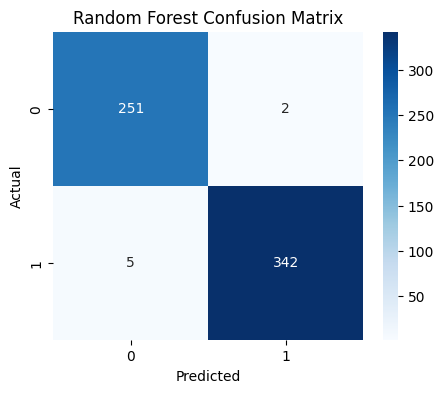

In [36]:
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()